# Loading calvdb from Hugging Face

Downloads one per-glacier archive from [`enscg/calvdb`](https://huggingface.co/datasets/enscg/calvdb) and reads it with **zarr** and with **xarray**.

The archives are read **directly — do not unzip them.** `zarr.storage.ZipStore` streams chunks straight out of the `.zip`.

---

## Environment requirements

### zarr-python >= 3.0 is mandatory

The stores are **Zarr format 3** (`"zarr_format": 3`). **zarr-python 2.x cannot read them at all** — it looks for `.zgroup` / `.zarray`, which v3 stores do not contain, and fails with:

```
GroupNotFoundError: group not found at path ''
```

If you see that error, check your version first — it means *wrong zarr version*, not a bad path:

```python
import zarr; print(zarr.__version__)   # must be 3.x
```

| Component | Requirement | Why |
|---|---|---|
| `zarr` | **>= 3.0** (tested 3.1.5) | Zarr v3 store; v2 raises `GroupNotFoundError` |
| Python | **>= 3.11** | hard floor of zarr-python 3.x |
| `numcodecs` | >= 0.14 | installed with zarr 3; provides the **zstd** codec |
| `numpy` | >= 1.26 | zarr 3 floor. See the numpy 2 note below |
| `xarray` | >= 2024.10 | optional, for the xarray route |
| `huggingface_hub` | any recent (tested 1.3.4) | download only |

```bash
conda create -n calvdb python=3.12 && conda activate calvdb
pip install "zarr>=3.0" huggingface_hub xarray numpy pandas matplotlib
```

Do **not** upgrade zarr inside an existing 2.x environment unless you are ready for the fallout — the 2→3 API change is breaking. Use a separate environment.

### numpy 2.x note

The `dates` array is `vlen-utf8`, which numpy >= 2 surfaces as `StringDType()`. `.astype(str)` on it raises `TypeError: cannot cast dtype StringDType()...` — use `.tolist()` instead, as below.

### Download size

One archive per glacier, 0.4 MB – 300 MB depending on glacier extent and record length (~5.4 GB for all 123). This notebook uses `RGI60-07.00552` (**30 MB**, 249 timesteps). `hf_hub_download` caches to `~/.cache/huggingface/`, so reruns are free.

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import zarr

print(f"python {sys.version.split()[0]}")
print(f"zarr   {zarr.__version__}")
print(f"numpy  {np.__version__}")

assert int(zarr.__version__.split(".")[0]) >= 3, (
    f"zarr {zarr.__version__} cannot read a Zarr v3 store — install zarr>=3.0"
)

python 3.13.11
zarr   3.1.5
numpy  2.2.6


In [ ]:
# Download one glacier archive (~30 MB, cached after the first run)
from huggingface_hub import hf_hub_download

GLACIER = "RGI60-07.00552"

zip_path = hf_hub_download(
    repo_id="enscg/calvdb",
    filename=f"zarr_zipped/{GLACIER}.zarr.zip",
    repo_type="dataset",
)

In [ ]:
# Method 1 — zarr. Read the .zip directly; no unzipping.
store = zarr.storage.ZipStore(zip_path, mode="r")
group = zarr.open_group(store, mode="r")

attrs = dict(group.attrs)
for k, v in attrs.items():
    print(f"{k:20s} {v}")

glacier_id           RGI60-07.00552
T                    249
H                    88
W                    127
resolution_m         30.0
crs                  EPSG:3995
sdt_clip_m           2000.0
dates_format         YYYY-MM-DD
img_channels         ['blue', 'green', 'red', 'nir', 'swir1']
geophys_channels     ['bed_elevation', 'surface_elevation', 'thickness', 'velocity', 'strain_rate', 'ice_fjord_mask']
climate_channels     ['mar_runoff', 'ocean_temp']
trace_description    Rasterised calving front line from Trace_MASK.tif. True pixels lie on the calving front only — no fjord boundary. Used for evaluation metrics only, not as a model input.


In [4]:
# Array inventory
pd.DataFrame(
    [
        {
            "array": k,
            "shape": group[k].shape,
            "dims": group[k].metadata.dimension_names,
            "dtype": str(group[k].dtype),
        }
        for k in sorted(group.array_keys())
    ]
).set_index("array")

,shape,dims,dtype
array,,,
climate,"(249, 2)","(time, climate_channel)",float32
dates,"(249,)","(time,)",StringDType()
geophys,"(249, 6, 88, 127)","(time, geo_channel, y, x)",float32
imagery,"(249, 5, 88, 127)","(time, band, y, x)",float32
sdt,"(249, 88, 127)","(time, y, x)",float32
sensors,"(249,)","(time,)",uint8
trace,"(249, 88, 127)","(time, y, x)",bool
valid_clm,"(249,)","(time,)",bool
valid_img,"(249,)","(time,)",bool


In [ ]:
# Method 2 — xarray. Same store object, named dimensions, lazy dask chunks.
import xarray as xr

ds = xr.open_zarr(zarr.storage.ZipStore(zip_path, mode="r"))
ds

<xarray.Dataset> Size: 136MB
Dimensions:      (time: 249, climate_channel: 2, geo_channel: 6, y: 88, x: 127,
                  band: 5)
Dimensions without coordinates: time, climate_channel, geo_channel, y, x, band
Data variables:
    climate      (time, climate_channel) float32 2kB dask.array<chunksize=(1, 2), meta=np.ndarray>
    dates        (time) object 2kB dask.array<chunksize=(249,), meta=np.ndarray>
    geophys      (time, geo_channel, y, x) float32 67MB dask.array<chunksize=(1, 6, 88, 127), meta=np.ndarray>
    imagery      (time, band, y, x) float32 56MB dask.array<chunksize=(1, 5, 88, 127), meta=np.ndarray>
    sdt          (time, y, x) float32 11MB dask.array<chunksize=(1, 88, 127), meta=np.ndarray>
    sensors      (time) uint8 249B dask.array<chunksize=(1,), meta=np.ndarray>
    trace        (time, y, x) bool 3MB dask.array<chunksize=(1, 88, 127), meta=np.ndarray>
    valid_clm    (time) bool 249B dask.array<chunksize=(1,), meta=np.ndarray>
    valid_img    (time) bool 249B dask.array<chunksize=(1,), meta=np.ndarray>
    valid_sdt    (time) bool 249B dask.array<chunksize=(1,), meta=np.ndarray>
    valid_trace  (time) bool 249B dask.array<chunksize=(1,), meta=np.ndarray>
Attributes:
    glacier_id:         RGI60-07.00552
    T:                  249
    H:                  88
    W:                  127
    resolution_m:       30.0
    crs:                EPSG:3995
    sdt_clip_m:         2000.0
    dates_format:       YYYY-MM-DD
    img_channels:       ['blue', 'green', 'red', 'nir', 'swir1']
    geophys_channels:   ['bed_elevation', 'surface_elevation', 'thickness', '...
    climate_channels:   ['mar_runoff', 'ocean_temp']
    trace_description:  Rasterised calving front line from Trace_MASK.tif. Tr...

In [6]:
# Observation record: date, sensor, validity flags
SENSOR_NAMES = {0: "S2", 1: "LE07", 2: "LC08", 3: "LC09", 255: "unknown"}

obs = pd.DataFrame(
    {
        "date": pd.to_datetime(group["dates"][:].tolist()),  # .tolist(), not .astype(str)
        "sensor": [SENSOR_NAMES.get(int(s), "unknown") for s in group["sensors"][:]],
        "valid_sdt": group["valid_sdt"][:],
        "valid_img": group["valid_img"][:],
        "valid_clm": group["valid_clm"][:],
        "valid_trace": group["valid_trace"][:],
    }
)
obs.index.name = "t"
print(f"T = {len(obs)}   {obs['date'].min().date()} \u2192 {obs['date'].max().date()}")
print(obs["sensor"].value_counts().to_string())
obs.head(10)

T = 249   2013-04-30 → 2022-09-28
sensor
S2      157
LC08     86
LC09      6


,date,sensor,valid_sdt,valid_img,valid_clm,valid_trace
t,,,,,,
0,2013-04-30,LC08,True,True,True,True
1,2013-09-10,LC08,True,True,True,True
2,2013-09-14,LC08,True,True,True,True
3,2013-09-19,LC08,True,True,True,True
4,2013-09-28,LC08,True,True,True,True
5,2014-06-04,LC08,True,True,True,True
6,2014-06-25,LC08,True,True,True,True
7,2014-07-15,LC08,True,True,True,True
8,2014-08-07,LC08,True,True,True,True


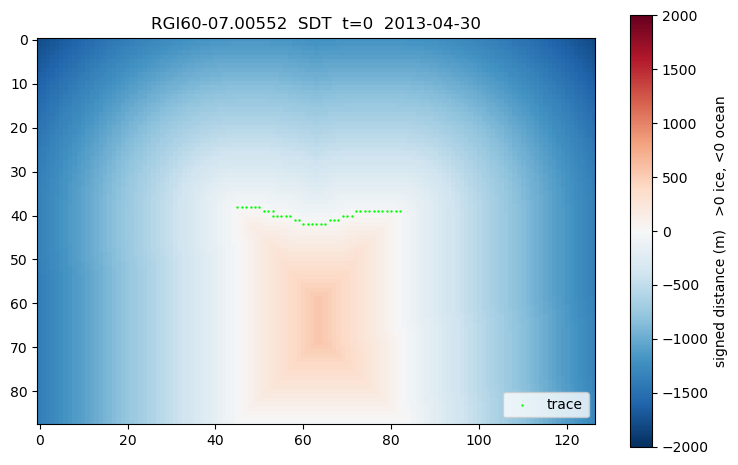

In [ ]:
# Signed distance transform at one timestep, with the calving front trace overlaid.
# SDT > 0 = ice, SDT < 0 = non-ice(ocean/bedrock); the front is the zero level set.
t = 0
sdt = group["sdt"][t]
trace = group["trace"][t]
clip = attrs["sdt_clip_m"]

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(sdt, cmap="RdBu_r", vmin=-clip, vmax=clip)
ys, xs = np.nonzero(trace)
ax.scatter(xs, ys, s=0.5, c="lime", label="trace")
ax.set_title(f"{attrs['glacier_id']}  SDT  t={t}  {obs.loc[t, 'date'].date()}")
ax.legend(loc="lower right")
fig.colorbar(im, ax=ax, shrink=0.8, label="signed distance (m)   >0 ice, <0 ocean")
plt.show()

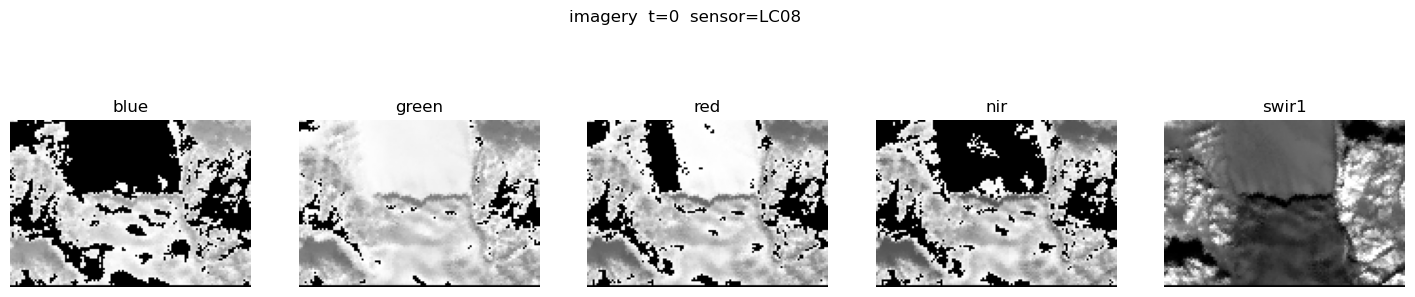

In [8]:
# Optical bands for the same timestep
imagery = group["imagery"][t]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, band, name in zip(axes, imagery, attrs["img_channels"]):
    lo, hi = np.percentile(band, [2, 98])
    ax.imshow(band, cmap="gray", vmin=lo, vmax=hi)
    ax.set_title(name)
    ax.axis("off")
fig.suptitle(f"imagery  t={t}  sensor={obs.loc[t, 'sensor']}")
plt.show()

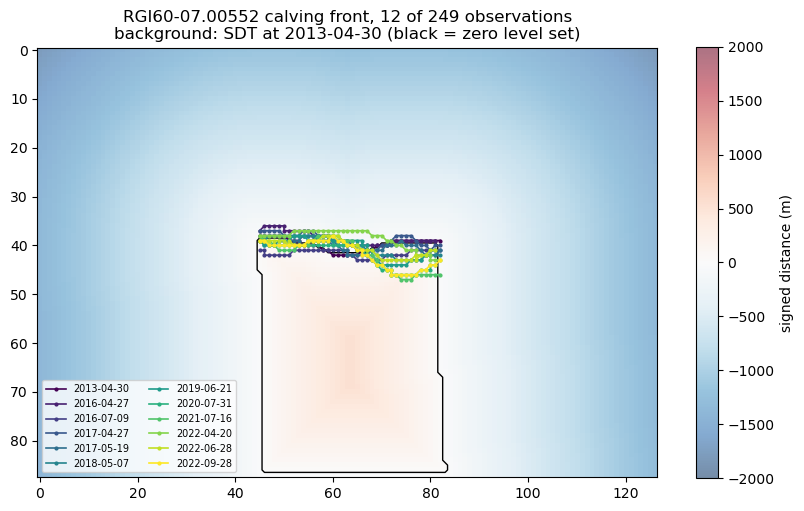

In [ ]:
# Front migration through time, over the SDT field at the first observation.
# Showing 12 evenly spaced observations 
t0 = 0
sdt_bg = group["sdt"][t0]
clip = attrs["sdt_clip_m"]

picks = np.linspace(0, len(obs) - 1, 12).astype(int)
cmap = plt.get_cmap("viridis")

fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(sdt_bg, cmap="RdBu_r", vmin=-clip, vmax=clip, alpha=0.55)
ax.contour(sdt_bg, levels=[0], colors="k", linewidths=1.0)

for i in picks:
    ys, xs = np.nonzero(group["trace"][i])
    order = np.argsort(xs)
    ax.plot(xs[order], ys[order], ".-", ms=4, lw=1.2,
            color=cmap(i / (len(obs) - 1)), label=str(obs.loc[i, "date"].date()))

# imshow already puts row 0 at the top — do not invert the y axis here
ax.set_title(f"{attrs['glacier_id']} calving front, 12 of {len(obs)} observations\n"
             f"background: SDT at {obs.loc[t0, 'date'].date()} (black = zero level set)")
ax.legend(fontsize=7, ncol=2, loc="lower left")
fig.colorbar(im, ax=ax, shrink=0.8, label="signed distance (m)")
plt.show()

In [ ]:
# Benchmark splits: each entry is one forecasting sample.
# `zarr_path` gives the repository-relative location of that glacier's archive.
import json

splits_path = hf_hub_download(
    repo_id="enscg/calvdb", filename="splits/test.json", repo_type="dataset"
)
test_split = json.load(open(splits_path))
print(f"{len(test_split)} test samples")

sample = test_split[0]
print(json.dumps(sample, indent=2))

archive = hf_hub_download(
    repo_id="enscg/calvdb", filename=sample["zarr_path"], repo_type="dataset"
)
g = zarr.open_group(zarr.storage.ZipStore(archive, mode="r"), mode="r")

inputs = g["sdt"][sample["input_zarr_indices"]]  # (5, H, W) history
target = g["sdt"][sample["target_zarr_index"]]  # (H, W) front 365 days ahead
print(f"\n{sample['glacier_id']}: inputs {inputs.shape}, target {target.shape}")

259 test samples
{
  "glacier_id": "RGI60-07.00030_D",
  "zarr_path": "zarr_zipped/RGI60-07.00030_D.zarr.zip",
  "reference_date": "2017-05-20",
  "horizon_days": 365,
  "input_zarr_indices": [
    0,
    5,
    7,
    14,
    22
  ],
  "target_zarr_index": 53,
  "input_days": [
    -1490.0,
    -1081.0,
    -677.0,
    -322.0,
    -48.0
  ],
  "target_day": 352.0,
  "day_gaps": [
    -30.0,
    14.0,
    53.0,
    43.0,
    -18.0
  ],
  "anchor_offsets": [
    -1460,
    -1095,
    -730,
    -365,
    -30
  ]
}

RGI60-07.00030_D: inputs (5, 109, 114), target (109, 114)
